In [25]:
!pip install keras

In [26]:
# 1. Import the packages
import keras
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.datasets import mnist

In [27]:
# 2. Load the dataset
(x_train,y_train),(x_test,y_test)=mnist.load_data()

In [28]:
# 3. Normalization
x_train=x_train/255
x_test=x_test/255

In [29]:
# 4. Build the Neural Network
model=Sequential()

# First layer
model.add(keras.layers.Flatten(input_shape=(28,28)))

# Hidden layer
model.add(keras.layers.Dense(128,activation='relu'))

# Output layer
model.add(keras.layers.Dense(10,activation='softmax'))

In [30]:
# 5. Compile the model
model.compile(optimizer='sgd',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [31]:
# 6. Train the model
H=model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8359 - loss: 0.6462 - val_accuracy: 0.9044 - val_loss: 0.3560
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9063 - loss: 0.3373 - val_accuracy: 0.9205 - val_loss: 0.2924
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9191 - loss: 0.2885 - val_accuracy: 0.9278 - val_loss: 0.2596
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9273 - loss: 0.2572 - val_accuracy: 0.9345 - val_loss: 0.2361
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9345 - loss: 0.2340 - val_accuracy: 0.9394 - val_loss: 0.2177


In [32]:
# 7. Evaluate
test_loss,test_acc=model.evaluate(x_test,y_test)
print("Loss: %.3f" % test_loss)
print("Accuracy: %.3f" % test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9394 - loss: 0.2177
Loss: 0.218
Accuracy: 0.939


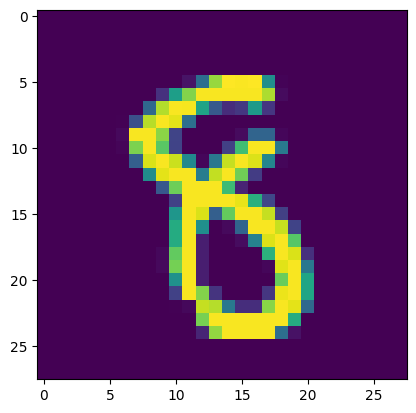

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
The handwritten number in the image is 8


In [33]:
# 8. Predict a digit
n=random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()
prediction=model.predict(x_test)
print("The handwritten number in the image is %d" % np.argmax(prediction[n]))

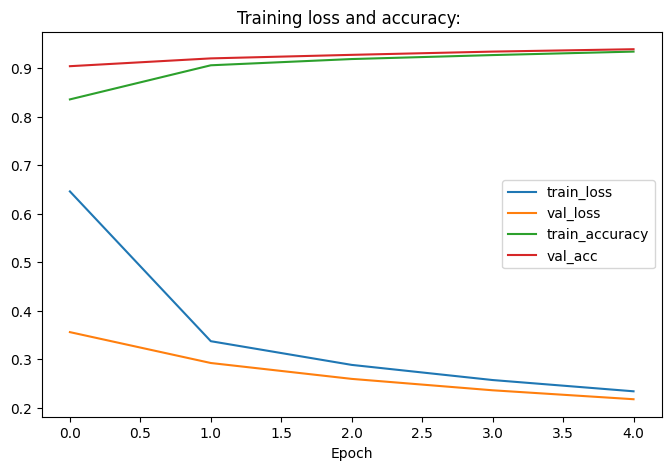

In [34]:
# 9. Plot graphs
plt.figure(figsize=(8,5))
plt.plot(H.history['loss'],label='train_loss')
plt.plot(H.history['val_loss'],label='val_loss')
plt.plot(H.history['accuracy'],label='train_accuracy')
plt.plot(H.history['val_accuracy'],label='val_acc')
plt.title("Training loss and accuracy: ")
plt.xlabel("Epoch")
plt.legend()
plt.show()